In [1]:
from pca_utils import *

# Import data

In [3]:
path1 = "/mnt/c/users/helen/Desktop/160226_Outsu_PCA/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/160226_Outsu_PCA/siPUS7/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/160226_Outsu_PCA/siPUS7/foci2/aggregated_data.csv"
path4 = "/mnt/c/users/helen/Desktop/160226_Outsu_PCA/siPUS7_MUT/foci2/aggregated_data.csv"


df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)
df4 = pd.read_csv(path4)


df1["sample"] = "Control"
df2["sample"] = "siPUS7"
df3["sample"] = "siPUS7 + PUS7 WT"
df4["sample"] = "siPUS7 + PUS7 MUT"


combined_df = pd.concat(
    [df1, df2, df3, df4],
    ignore_index=True
)

In [ ]:
path1 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/MGS1/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/MGS2/foci2/aggregated_data.csv"
path4 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/MGS3/foci2/aggregated_data.csv"
path5 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/MGS4/foci2/aggregated_data.csv"
path6 = "/mnt/c/users/helen/Desktop/190226_Outsu_PCA/MGS5/foci2/aggregated_data.csv"

df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)
df4 = pd.read_csv(path4)
df5 = pd.read_csv(path5)
df6 = pd.read_csv(path6)

df1["sample"] = "WT"
df2["sample"] = "MGS1"
df3["sample"] = "MGS2"
df4["sample"] = "MGS3"
df5["sample"] = "MGS4"
df6["sample"] = "MGS5"

combined_df = pd.concat(
    [df1, df2, df3, df4, df5, df6],
    ignore_index=True
)

### Clean data

In [4]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 149


In [5]:
df.to_csv("160226_PUS7.csv")

# Correlation analysis

In [6]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
n_foci,1.000,-0.498,-0.498,0.543,0.557,-0.511,-0.708,-0.709,-0.713
area,-0.498,1.000,1.000,-0.765,-0.739,0.815,0.712,0.716,0.703
equivalent_diameter_area,-0.498,1.000,1.000,-0.765,-0.739,0.815,0.712,0.716,0.703
eccentricity,0.543,-0.765,-0.765,1.000,0.582,-0.867,-0.733,-0.740,-0.722
solidity,0.557,-0.739,-0.739,0.582,1.000,-0.670,-0.585,-0.591,-0.581
perimeter,-0.511,0.815,0.815,-0.867,-0.670,1.000,0.736,0.742,0.725
mean_intensity,-0.708,0.712,0.712,-0.733,-0.585,0.736,1.000,0.999,0.998
max_intensity,-0.709,0.716,0.716,-0.740,-0.591,0.742,0.999,1.000,0.998
min_intensity,-0.713,0.703,0.703,-0.722,-0.581,0.725,0.998,0.998,1.000


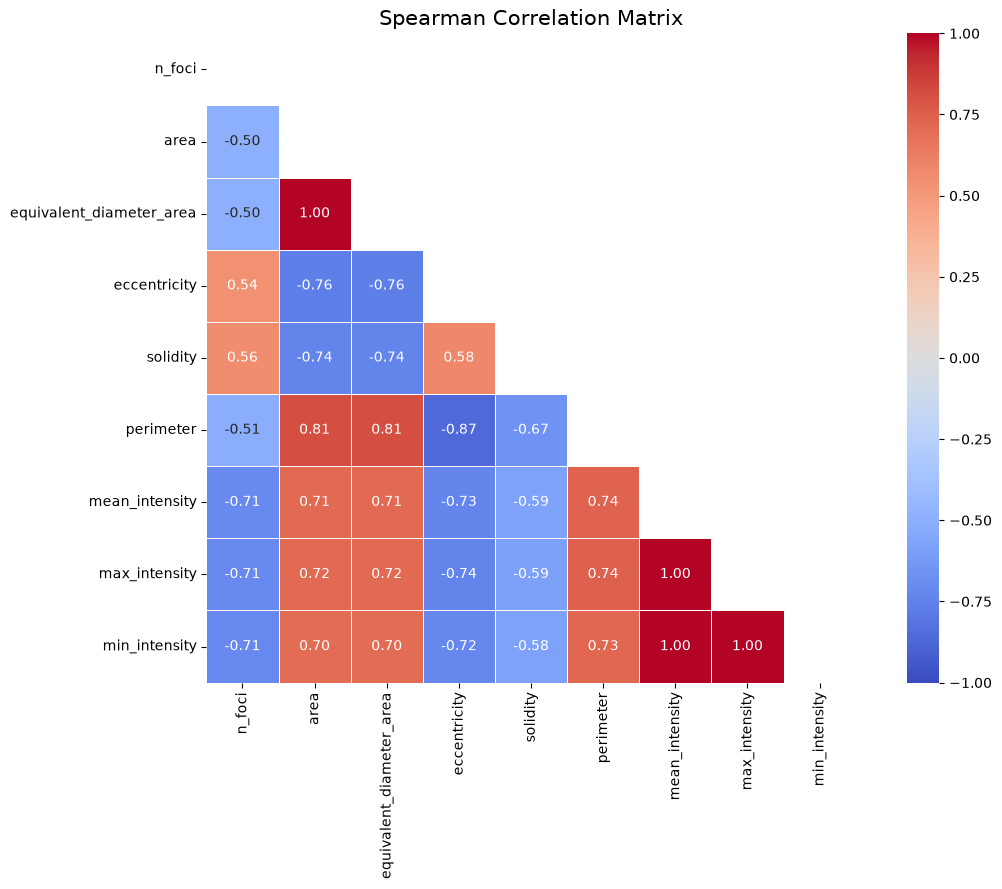

In [7]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

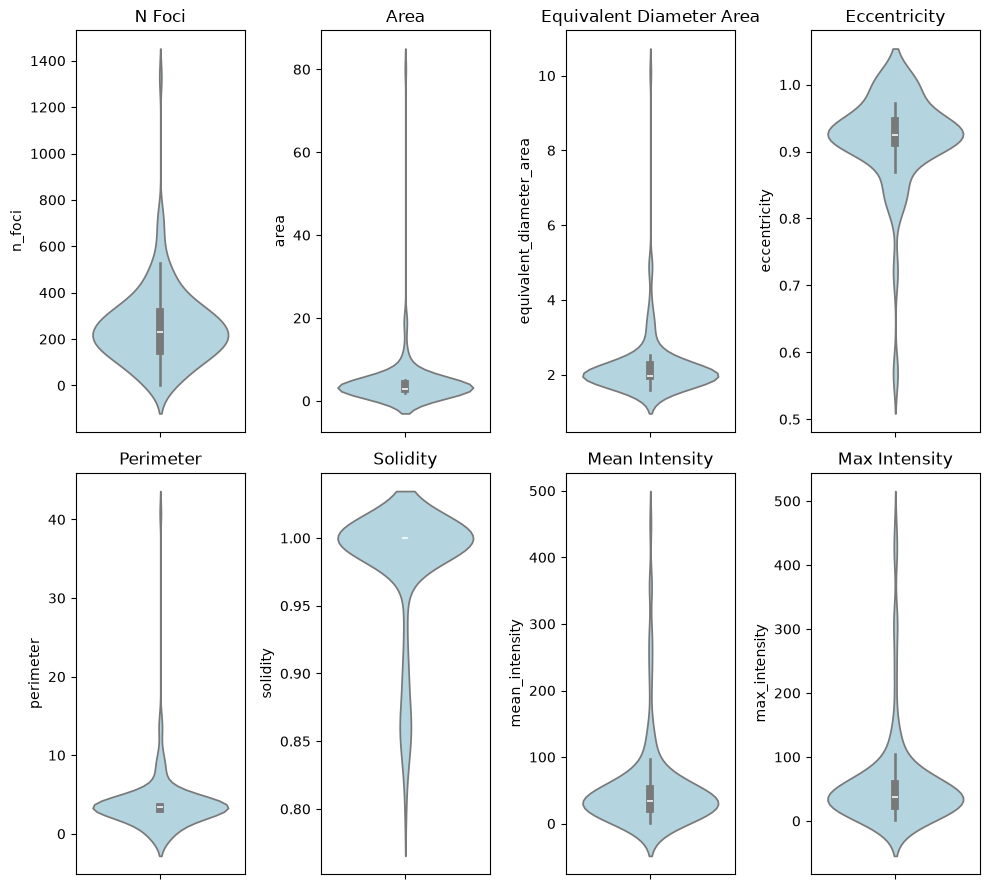

In [8]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(2, 4, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [9]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
    #"min_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

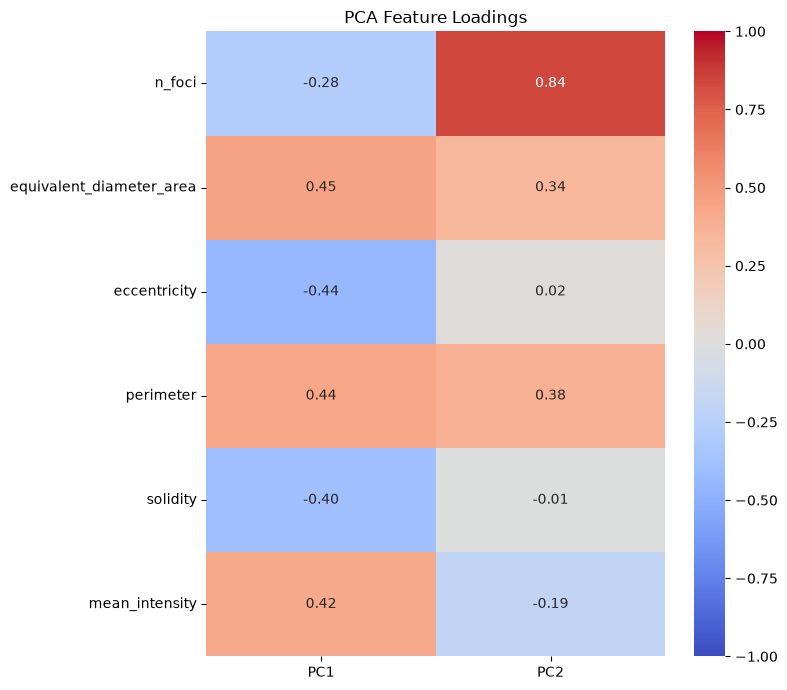

In [10]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [11]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

                        PC1       PC2
sample                               
Control           -0.115140  0.201413
siPUS7             0.046529 -0.135171
siPUS7 + PUS7 MUT  0.325359 -0.487399
siPUS7 + PUS7 WT   0.046529 -0.135171


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

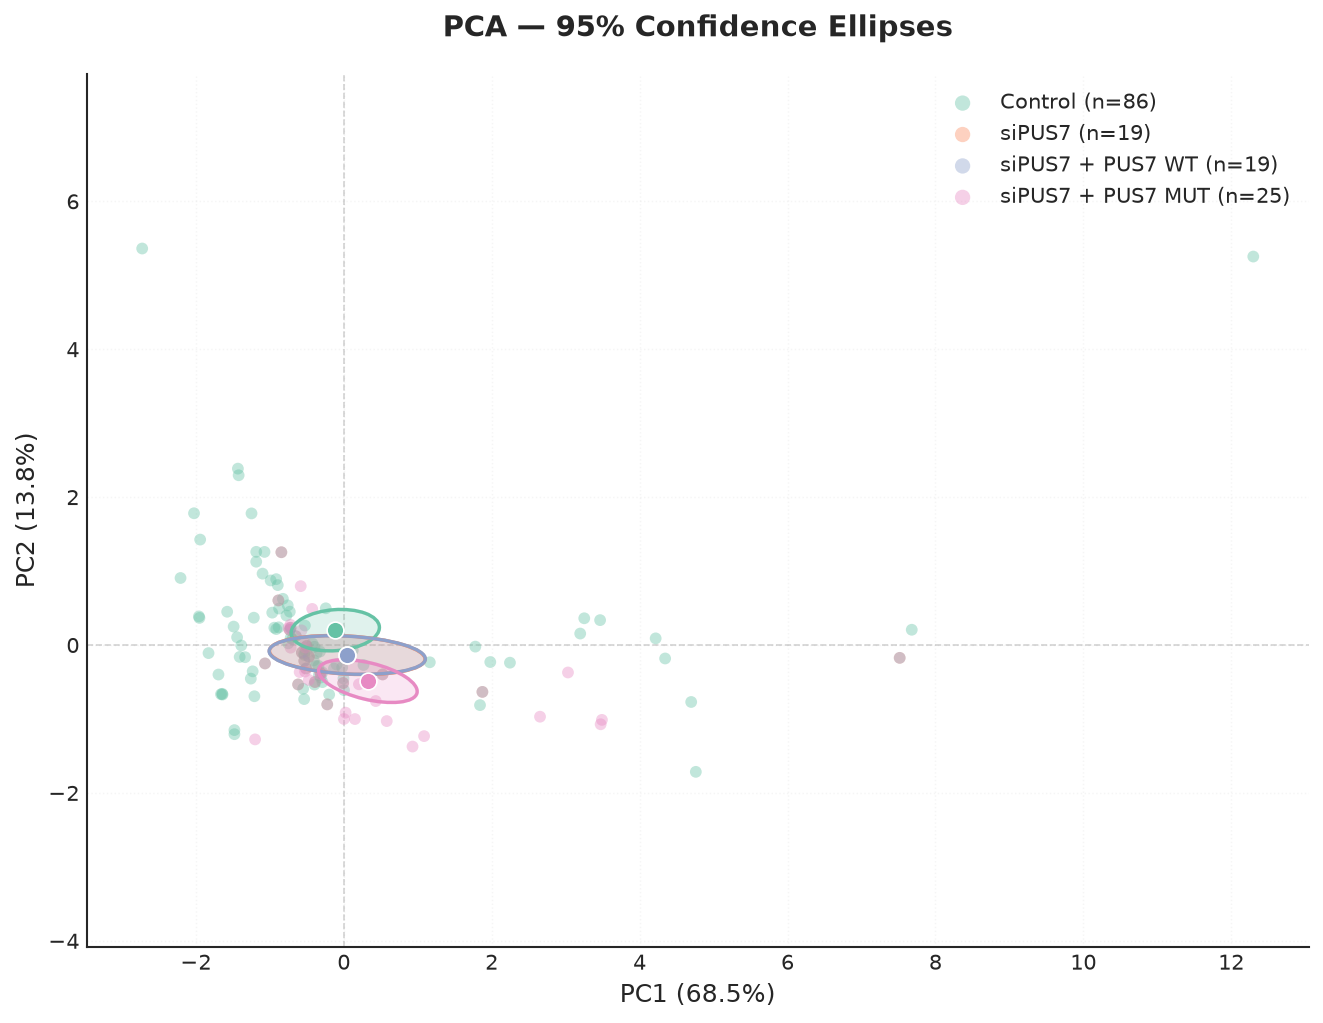

In [12]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    pca=pca,
    confidence=0.95,
    palette="Set2",
    centroid_size=65,
    show_bootstrap=False
)

In [13]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,0.935918,0.4277,0.018996,149,4
1,PERMDISP,0.889566,0.4397,NaN,149,4


In [ ]:
subset = pca_df[(pca_df['sample'] == "Control") | (pca_df['sample'] == "Pyridostatin, 20 uM")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "Control") | (pca_df['sample'] == "Pyridostatin, 5 uM")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

### Centroids distances tree

In [ ]:
distances = plot_centroid_distance_tree(
    results,
    reference="Control",
    palette="Set2"
)

# Detect outliers

In [ ]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

In [ ]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

In [ ]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [ ]:
distances = plot_centroid_distance_tree(
    results,
    reference="Control",
    palette="Set2"
)

In [ ]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "Control") | (pca_df['sample'] == "Pyridostatin, 5 uM")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats